In [2]:
!pip install pandas numpy matplotlib scikit-learn tensorflow


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/content/household_power_consumption.txt",
    sep=";",
    na_values="?",
    low_memory=False
)

print("Dataset loaded successfully!")
print(df.head())
print("Dataset shape:", df.shape)
print("Missing values:")
print(df.isnull().sum())

Dataset loaded successfully!
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  
Dataset shape: (2075259, 9)
Missing values:
Date                      

In [4]:

# Convert numerical columns into numbers
features = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing values
df[features] = df[features].interpolate(
    method="linear",
    limit_direction="both"
)

# Check missing values again
print("Missing values after filling:")
print(df[features].isnull().sum())

# Select 10,000 consecutive records
df = df.iloc[:10000].copy()

print("\nSelected dataset shape:", df.shape)
print(df.head())


Missing values after filling:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

Selected dataset shape: (10000, 9)
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0      

In [5]:

from sklearn.preprocessing import MinMaxScaler

# Normalize numerical features
scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(df[features])

print("Normalization completed!")
print("Scaled data shape:", scaled_data.shape)
print("\nFirst 5 normalized records:")
print(scaled_data[:5])


Normalization completed!
Scaled data shape: (10000, 7)

First 5 normalized records:
[[0.52301691 0.57734807 0.28828391 0.52694611 0.         0.01369863
  0.85      ]
 [0.67178153 0.60220994 0.22946038 0.66467066 0.         0.01369863
  0.8       ]
 [0.67360208 0.6878453  0.21293145 0.66467066 0.         0.02739726
  0.85      ]
 [0.67542263 0.69337017 0.23480797 0.66467066 0.         0.01369863
  0.85      ]
 [0.45149545 0.72928177 0.32912008 0.4491018  0.         0.01369863
  0.85      ]]


In [6]:

# Create sequences for LSTM
window = 60

X = []
y = []

# Predict Global_active_power
target_index = features.index("Global_active_power")

for i in range(window, len(scaled_data)):
    X.append(scaled_data[i-window:i])
    y.append(scaled_data[i, target_index])

X = np.array(X)
y = np.array(y)

print("Sequence creation completed!")
print("X shape:", X.shape)
print("y shape:", y.shape)

Sequence creation completed!
X shape: (9940, 60, 7)
y shape: (9940,)


In [7]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Build LSTM model
model = Sequential([
    LSTM(32, input_shape=(60, 7)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mse"
)

# Display model architecture
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,665 (22.13 KB)

 Trainable params: 5,665 (22.13 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:

# Split data into training and testing sets
split = int(len(X) * 0.8)

X_train = X[:split]
y_train = y[:split]

X_test = X[split:]
y_test = y[split:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Train the LSTM model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=False
)


Training data: (7952, 60, 7)
Testing data: (1988, 60, 7)
Epoch 1/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - loss: 0.0156 - val_loss: 0.0034
Epoch 2/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0094 - val_loss: 0.0024
Epoch 3/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0071 - val_loss: 0.0019
Epoch 4/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 0.0057 - val_loss: 0.0017
Epoch 5/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0053 - val_loss: 0.0016
Epoch 6/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0049 - val_loss: 0.0015
Epoch 7/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0046 - val_loss: 0.0014
Epoch 8/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0045 - val_loss: 0.0015
Epoch 9/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0043 - val_loss: 0.0015
Epoch 10/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0043 - val_loss: 0.0013


In [9]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict on unseen test data
predictions = model.predict(X_test)

# Convert normalized values back to actual kW
actual = scaler.inverse_transform(
    np.column_stack([
        np.zeros((len(y_test), target_index)),
        y_test,
        np.zeros((len(y_test), len(features) - target_index - 1))
    ])
)[:, target_index]

predicted = predictions.flatten() * (
    scaler.data_max_[target_index] - scaler.data_min_[target_index]
) + scaler.data_min_[target_index]

# Calculate MAE and RMSE
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MAE:", round(mae, 4), "kW")
print("RMSE:", round(rmse, 4), "kW")


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
MAE: 0.6098 kW
RMSE: 0.7851 kW


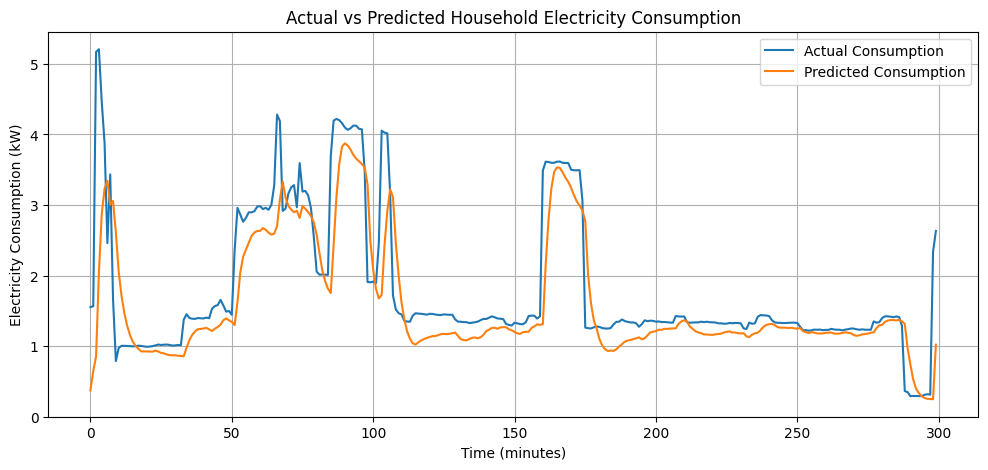

In [10]:

plt.figure(figsize=(12, 5))

plt.plot(actual[:300], label="Actual Consumption")
plt.plot(predicted[:300], label="Predicted Consumption")

plt.xlabel("Time (minutes)")
plt.ylabel("Electricity Consumption (kW)")
plt.title("Actual vs Predicted Household Electricity Consumption")

plt.legend()
plt.grid(True)
plt.show()

In [11]:

from sklearn.metrics import r2_score

r2 = r2_score(actual, predicted)

print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")


R2 Score: 0.6719
R2 Percentage: 67.19 %


In [12]:

import numpy as np

# Approximate prediction accuracy based on MAE
accuracy = 100 * (1 - np.mean(np.abs(actual - predicted)) /
                  np.mean(np.abs(actual)))

print("Approximate Prediction Accuracy:",
      round(accuracy, 2), "%")



Approximate Prediction Accuracy: 75.16 %
